# Automatic aircraft detection in 2 × 2 km Sentinel-2 chips

Can simple image processing find the aircraft that was labelled by hand (`x`/`y` in the collocation CSV)?
For every Sentinel-2 collocation a 2 × 2 km chip (200 × 200 px at 10 m) is cut around the manual location, with
B02 (blue), B03 (green), B04 (red) and B10 (cirrus, 60 m, nearest-neighbour upsampled). Three random chips per
granule, at least 5 km from the aircraft, serve as **negatives**, so the detector is also tested on scenes
without an aircraft.

**Evaluation.** Each method returns one location and a score per chip. A chip is *accepted* when score ≥ τ.
- TP: accepted positive chip, detection ≤ 100 m from the manual location
- FP: accepted negative chip, or accepted positive chip with the detection > 100 m away
- precision = TP / accepted, recall = TP / positive chips

τ is tuned with granule-level **2-fold cross-validation** (tune on one half, evaluate on the other, swap).
The chips are centred on the manual location, so no method may use the chip centre: the only spatial
restriction is a 100 m frame along the chip edge where the filters are unreliable.

**Physics used.**
- Sentinel-2 records B02, B03 and B04 a fraction of a second apart. A moving aircraft therefore appears as three
  displaced blobs (blue and red ~60–150 m on opposite sides of green), while static clouds and ground are
  co-located in all bands. Comparing green with the other two visible bands removes most of the background.
  The manual labels sit on the green blob, so green is the reference band.
- Over dark surfaces the aircraft is **brighter** than its surroundings. Over bright cloud it is **darker**
  (white paint ≈ 0.4 vs thick cloud ≈ 0.8 reflectance), so the green signal is used *signed*.
- B10 is absorbed by water vapour, so it mainly sees objects high in the atmosphere. It confirms the aircraft,
  but it is recorded at yet another time (its blob is offset from green) and only at 60 m. It is therefore a
  capped, down-weighted term that does not set the position.
- Low cumulus clouds also move and show a slight colour offset, but they are much **larger** than an aircraft
  in B10. Detections whose B10 object exceeds 250 px (0.025 km²) are rejected.
- Sentinel-2 images a tile with 12 staggered detectors. At a **detector border** the same aircraft can appear
  **twice**, on neighbouring detectors and with the blue/red order reversed in the copy. The detector warns
  about this. The detector footprints come from the granule's `MSK_DETFOO_B03` mask (jp2 or GML), read via
  pycontrails' Sentinel handler.

Code: `src/iagos_toolkit/imagery/chips.py` (download/chips) and `src/iagos_toolkit/imagery/aircraft_detection.py`
(methods, duplicate check, metrics).

**Note:** building the chip cache downloads ~400 Sentinel-2 granules (~1 h). The full tiles are deleted
right after cropping; the chips take ~360 MB in `../data/aircraft_chips/` (git-ignored).

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from iagos_toolkit.imagery import aircraft_detection as ad
from iagos_toolkit.imagery.chips import (EXCLUDED_CHIPS, add_detector_info, build_chip_cache,
                                          drop_near_detector_border, load_chips,
                                          load_sentinel_collocations)

CSV = "../data/landsat_sentinel_collocations_20260216.csv"
CHIP_DIR = Path("../data/aircraft_chips")
FIG_DIR = Path("../figures")
N_JOBS = 8
TOL = 100.0  # m, match tolerance
FINAL = ad.FINAL_METHOD

## 1. Collocations and exclusions

In [2]:
df, excluded = load_sentinel_collocations(CSV)
print(f"{len(df)} usable Sentinel-2 collocations, {len(excluded)} excluded")
excluded[["row", "scene_id", "exclude_reason"]]

412 usable Sentinel-2 collocations, 9 excluded


,row,scene_id,exclude_reason
345,345,L1C_T17TNJ_A035930_20220509T162807,out_of_frame_flag
474,474,L1C_T16TDP_A012779_20190817T165911,out_of_frame_flag
548,548,L1C_T18TWL_A020929_20190625T155629,x/y outside extent
565,565,L1C_T10TGS_A020888_20190622T190618,out_of_frame_flag
579,579,L1C_T31UDQ_A020383_20210130T105205,out_of_frame_flag
603,603,L1C_T29UQR_A032924_20211011T112452,out_of_frame_flag
628,628,L1C_T25SDD_A032496_20210911T131028,out_of_frame_flag
711,711,L1C_T31TGN_A016450_20180816T104419,x/y outside extent
716,716,L1C_T10SGD_A008819_20181113T184729,x/y outside extent


## 2. Chip cache

Granules that already have chips are skipped. Chips that would cross the tile edge or contain nodata are
skipped and logged. Chips listed in `EXCLUDED_CHIPS` were removed after visual inspection.

In [3]:
with tempfile.TemporaryDirectory() as tmp:
    log = build_chip_cache(df, CHIP_DIR, cache_dir=tmp, n_neg=3, seed=0, max_workers=6)
    # detector id + distance to the nearest detector border for every chip pixel
    det_log = add_detector_info(df, CHIP_DIR, cache_dir=tmp, max_workers=8)
if len(log):
    print(log.status.value_counts())
print(det_log.status.value_counts().to_string())

chips = load_chips(CHIP_DIR)
n_pos = sum(c["label"] for c in chips)
print(f"{n_pos} positive and {len(chips) - n_pos} negative chips")
print("excluded after inspection:", EXCLUDED_CHIPS)
missing = sorted(set(df.row) - {c["row"] for c in chips if c["label"] == 1})
print("positives without chip (tile edge / nodata):", missing)

status
cached    412


405 positive and 1234 negative chips
excluded after inspection: {'neg_0467_2': 'random negative that contains a real aircraft', 'neg_0540_1': 'random negative that contains a real aircraft'}
positives without chip (tile edge / nodata): [426, 534, 576, 680, 754, 755, 761]


## 3. Methods

Every method is a response map (z = (value − median) / (1.4826 · MAD) over the chip). Its arg-max is the
detected location and its value is the score. Top-hat = band minus its 70 m median filter, smoothed with σ = 10 m.

| method | response map |
|---|---|
| `green_tophat` | z(top-hat₁₅₀ ₘ(B03)) |
| `cirrus_anomaly` | z(top-hat₁₉₀ ₘ(B10)) |
| `green_minus_red` | z(top-hat(B03 − B04)) |
| `green_minus_blue` | z(top-hat(B03 − B02)) |
| `green_excess` | z(top-hat(B03) − max(top-hat(B02), top-hat(B04))): green brighter than both |
| `green_signed` | max(z(green excess), z(green deficit)); deficit = min(top-hat(B02), top-hat(B04)) − top-hat(B03) |
| `green_cirrus_capped` | z(green excess) + 0.75 · min(z(cirrus), 30) |
| `signed_green_cirrus_capped` | green_signed + 0.75 · min(z(cirrus), 30) |
| **`signed_green_cirrus_capped_sized`** | **as above, rejecting detections whose B10 object is > 250 px (too large for an aircraft) or that lie < 20 m from a detector border** |

Subtracting only red or only blue removes the background in one of the two bands. A static feature that is
bright in green and in the other band still survives. Green excess takes the maximum of both, so it removes
the background from both bands at once.

The cap stops bright cumulus tops, which have huge B10 anomalies but little green signal, from being detected
on the cirrus term alone.

**Size gate.** `ad.cirrus_blob_area` measures the B10 object at the detection: the connected region above half
of the B10 top-hat peak near the detection. An aircraft gives ~50–160 px at 10 m (95th percentile 159 px).
The low cumulus behind most false alarms are larger (median 180 px, up to > 400 px). Only the detection itself
is gated: re-ranking the top-5 peaks by size did not help, because an aircraft over cirrus can itself sit on a
large B10 object. The green blob is *not* a useful size criterion: false alarms there are smaller than aircraft.

Tried and dropped because they did *not* improve the cross-validated result:
- symmetric blue/red "triplet" matching
- snapping the location to the nearest green maximum or to the ghost midpoint
- line-suppressing top-hats and a Hessian blob filter
- a ghost-amplitude gate and a B10/visible "height" ratio gate

Once the signed green signal was used, snapping became unnecessary: the location already sits on the green
blob (median error ~8 m).

In [4]:
res = ad.run_detectors(chips, n_jobs=N_JOBS)  # all detectors in ad.DETECTORS

rows = []
for method, r in res.groupby("method", sort=False):
    cv = ad.cross_validate(r, tol=TOL)
    rows.append({
        "method": method,
        "loc. recall (no threshold)": ad.evaluate(r, -np.inf, TOL)["loc_recall"],
        "CV precision": cv.precision.mean(), "CV recall": cv.recall.mean(),
        "worst-fold P": cv.precision.min(), "worst-fold R": cv.recall.min(),
        "CV specificity": cv.specificity.mean(), "τ (fold 0 / 1)": " / ".join(f"{t:.1f}" for t in cv.threshold),
        "median error [m]": r.loc[r.label == 1, "dist"].median(),
    })
summary = pd.DataFrame(rows).set_index("method")
summary.round(3)

,loc. recall (no threshold),CV precision,CV recall,worst-fold P,worst-fold R,CV specificity,τ (fold 0 / 1),median error [m]
method,,,,,,,,
green_tophat,0.709,0.473,0.489,0.464,0.448,0.840,27.5 / 28.0,10.129
cirrus_anomaly,0.820,0.770,0.756,0.749,0.744,0.959,17.6 / 18.5,70.833
green_minus_red,0.901,0.802,0.810,0.767,0.807,0.947,24.8 / 22.8,8.498
green_minus_blue,0.886,0.780,0.793,0.757,0.787,0.942,28.0 / 26.2,8.331
green_excess,0.891,0.854,0.852,0.840,0.828,0.960,12.3 / 12.3,8.484
green_signed,0.968,0.927,0.921,0.900,0.911,0.981,17.6 / 16.4,7.910
green_cirrus_capped,0.946,0.922,0.901,0.917,0.877,0.981,24.3 / 24.6,8.564
signed_green_cirrus_capped,0.975,0.936,0.941,0.923,0.941,0.985,26.4 / 25.4,8.142
signed_green_cirrus_capped_sized,0.975,0.950,0.936,0.945,0.931,0.989,25.2 / 25.4,8.142


*loc. recall* is the share of positive chips whose arg-max lies within 100 m of the label, i.e. the
ceiling on recall before any threshold. Precision is limited by how many negatives still produce a
high score.

## 4. Precision–recall over the score threshold (all chips pooled)

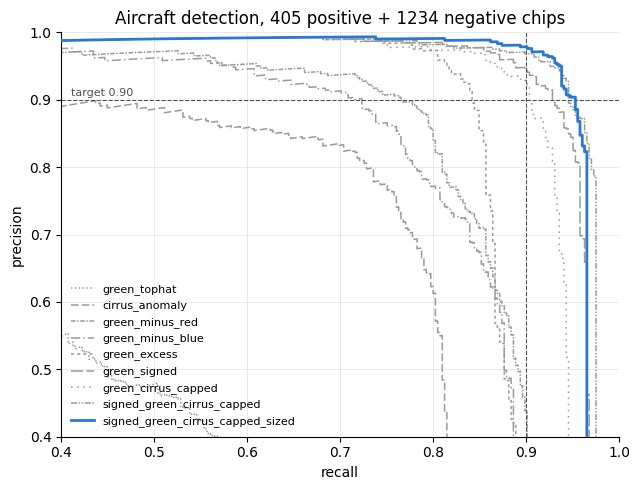

In [5]:
INK, MUTED, ACCENT = "#0b0b0b", "#9c9b95", "#2a78d6"

fig, ax = plt.subplots(figsize=(6.5, 5))
styles = iter([(0, (1, 1.5)), (0, (5, 2)), (0, (3, 1, 1, 1)), (0, (6, 2, 1, 2)), (0, (2, 2)),
               (0, (8, 2)), (0, (1, 3)), (0, (4, 1, 1, 1, 1, 1)), "-"])
for method, r in res.groupby("method", sort=False):
    pr = ad.pr_curve(r, TOL)
    final = method == FINAL
    ax.plot(pr.recall, pr.precision, lw=2 if final else 1.1, color=ACCENT if final else MUTED,
            ls="-" if final else next(styles), zorder=3 if final else 2, label=method)
ax.axhline(0.9, color="#52514e", lw=0.8, ls="--"); ax.axvline(0.9, color="#52514e", lw=0.8, ls="--")
ax.text(0.41, 0.905, "target 0.90", fontsize=8, color="#52514e")
ax.set(xlim=(0.4, 1), ylim=(0.4, 1.0), xlabel="recall", ylabel="precision",
       title=f"Aircraft detection, {n_pos} positive + {len(chips) - n_pos} negative chips")
ax.grid(color="#e6e5e0", lw=0.6); ax.set_axisbelow(True)
ax.legend(loc="lower left", fontsize=8, frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "aircraft_detection_pr.png", dpi=300)

## 5. Operating point of the final method

In [6]:
r = res[res.method == FINAL].reset_index(drop=True)
best = ad.best_threshold(r, TOL)
TAU = best["threshold"]
op = ad.evaluate(r, TAU, TOL)
print(f"pooled τ = {TAU:.1f}: precision {op['precision']:.3f}, recall {op['recall']:.3f}, "
      f"specificity {op['specificity']:.3f}")
print(ad.cross_validate(r, tol=TOL).round(3).to_string(index=False))
print("rejected by the size gate (label 0/1):", (r.rejected == "cirrus object too large").groupby(r.label).sum().to_dict())

acc, pos, near = r.score >= TAU, r.label == 1, r.dist <= TOL
breakdown = pd.Series({
    "positive: accepted, ≤100 m (TP)": (acc & pos & near).sum(),
    "positive: accepted, >100 m (FP + FN)": (acc & pos & ~near).sum(),
    "positive: below τ, location right (FN)": (~acc & pos & near).sum(),
    "positive: below τ, location wrong (FN)": (~acc & pos & ~near).sum(),
    "negative: accepted (FP)": (acc & ~pos).sum(),
    "negative: rejected (TN)": (~acc & ~pos).sum(),
})
breakdown.to_frame("chips")

pooled τ = 25.2: precision 0.950, recall 0.938, specificity 0.989
 fold  threshold  tune_P  tune_R  precision  recall  specificity  tp  fp  fp_on_negatives
    0     25.159   0.945   0.936      0.955   0.941        0.989 190   9                7
    1     25.393   0.960   0.941      0.945   0.931        0.990 189  11                6
rejected by the size gate (label 0/1): {0: 118, 1: 4}


,chips
"positive: accepted, ≤100 m (TP)",380
"positive: accepted, >100 m (FP + FN)",7
"positive: below τ, location right (FN)",15
"positive: below τ, location wrong (FN)",3
negative: accepted (FP),13
negative: rejected (TN),1221


## 6. Detector borders

`det_border_m` in each chip is the distance from every pixel to the nearest detector border. It is computed on
a window 500 m larger than the chip, so borders just outside it count too. Are detections near a border more
often wrong?

In [7]:
cls = np.select([pos & acc & near, pos, acc], ["TP", "positive, missed / > 100 m", "FP (negative)"], "TN (negative)")
pd.DataFrame({"class": cls, "within 100 m": r.border_dist < 100, "within 250 m": r.border_dist < 250}) \
    .groupby("class").agg(chips=("within 100 m", "size"), within_100m=("within 100 m", "mean"),
                          within_250m=("within 250 m", "mean")).round(3)

,chips,within_100m,within_250m
class,,,
FP (negative),13,0.000,0.000
TN (negative),1221,0.033,0.040
TP,380,0.005,0.018
"positive, missed / > 100 m",25,0.000,0.080


False alarms lie within 100 m of a detector border more often than the rest, but the border is only a minor
cause of them. To avoid such input data altogether, whole chips can be removed with
`drop_near_detector_border(chips, max_dist)`. It uses only the chip, never the label. The final detector rejects individual
detections within 20 m of a border (`min_border_dist`). Larger distances start to cost aircraft:

In [8]:
r_raw = r.copy()
r_raw["score"] = np.where(r_raw.rejected == "near detector border", r_raw.score_raw, r_raw.score)
rows = []
for bd in (0, 20, 50, 100, 200):
    d = r_raw.copy()
    d.loc[d.border_dist < bd, "score"] = -np.inf
    cv = ad.cross_validate(d, tol=TOL)
    rows.append({"reject detections within [m]": bd, "CV precision": cv.precision.mean(), "CV recall": cv.recall.mean(),
                 "worst fold": min(cv.precision.min(), cv.recall.min())})
pd.DataFrame(rows).round(3)

,reject detections within [m],CV precision,CV recall,worst fold
0,0,0.948,0.936,0.931
1,20,0.950,0.936,0.931
2,50,0.950,0.933,0.931
3,100,0.950,0.931,0.931
4,200,0.933,0.926,0.913


Whole chips can also be removed with `drop_near_detector_border(chips, max_dist)`, which uses only the
chip, never the label:

In [9]:
rows = []
for d in (0, 100, 200, 500):
    kept, dropped = drop_near_detector_border(chips, d) if d else (chips, [])
    rr = r[r.chip.isin({c["name"] for c in kept})]
    cv = ad.cross_validate(rr, tol=TOL)
    rows.append({"drop chips within [m]": d, "dropped chips": len(dropped),
                 "dropped positives": sum(n.startswith("pos") for n in dropped),
                 "CV precision": cv.precision.mean(), "CV recall": cv.recall.mean(),
                 "worst fold": min(cv.precision.min(), cv.recall.min())})
pd.DataFrame(rows).round(3)

,drop chips within [m],dropped chips,dropped positives,CV precision,CV recall,worst fold
0,0,0,0,0.950,0.936,0.931
1,100,159,36,0.956,0.938,0.935
2,200,174,37,0.958,0.938,0.935
3,500,216,50,0.957,0.938,0.932


Dropping chips near borders gains ~0.01 precision but costs ~9 % of the aircraft, so it is not part of the
default evaluation.

## 7. Duplicate aircraft

`ad.detect(chip, threshold=τ)` also looks for the second-strongest peak at least 250 m away. It issues a
`UserWarning` when that peak:
- scores ≥ 0.8 × the first peak and ≥ τ,
- lies within 2 km, and
- shows the **reversed** blue→red ghost direction (cosine < −0.5), and
- lies on a **different detector** than the first peak (when detector information is available).

That combination is what a copy of the same aircraft from the neighbouring detector looks like. Here the same
check runs on the whole table with `ad.flag_duplicates`.

In [10]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    r = ad.flag_duplicates(r, TAU)
for w in caught:
    print("WARNING:", w.message)
r.loc[r.duplicate, ["chip", "label", "score", "score2", "detector", "detector2", "ghost_cos", "border_dist", "dist"]].round(2)

,chip,label,score,score2,detector,detector2,ghost_cos,border_dist,dist
1310,pos_0419,1,105.35,104.04,9,10,-0.87,359.03,4.11
1371,pos_0482,1,394.45,373.30,1,2,-1.00,246.98,828.80
1395,pos_0506,1,268.44,256.94,7,8,-1.00,327.57,726.60
1401,pos_0512,1,119.26,112.66,6,5,-1.00,224.72,2.98
1408,pos_0519,1,102.38,96.80,10,11,-1.00,145.60,5.98
1444,pos_0557,1,140.77,136.45,6,5,-1.00,110.45,1.22


## 8. Galleries

For each chip: true colour (1–99.8 % stretch), B10, the response map of `GALLERY_METHOD` (what the method
"sees", its arg-max is the detection), and a 500 m zoom on the detection. Cyan circle = manual label,
red + = detection, orange × = second peak when flagged as a duplicate, white lines = detector borders. Change
`GALLERY_METHOD` to any key of `ad.DETECTORS` to see another method's view; detections and scores in the titles
always come from that method ("REJ" = rejected by the size gate or the border rule). The zoom is white where
it extends beyond the chip.

available methods: ['green_tophat', 'cirrus_anomaly', 'green_minus_red', 'green_minus_blue', 'green_excess', 'green_signed', 'green_cirrus_capped', 'signed_green_cirrus_capped', 'signed_green_cirrus_capped_sized']


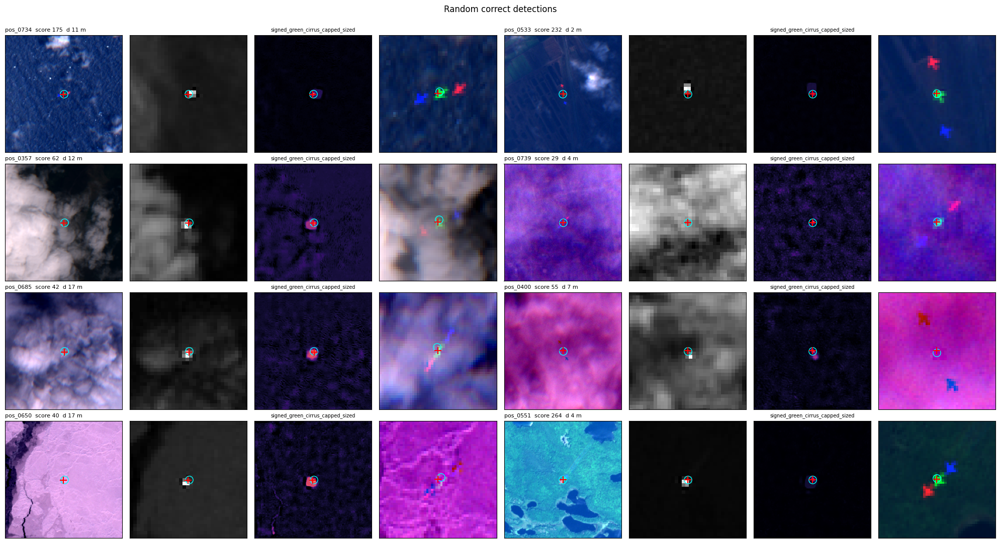

In [11]:
GALLERY_METHOD = FINAL  # any key of ad.DETECTORS, e.g. "green_excess", "cirrus_anomaly"
print("available methods:", list(ad.DETECTORS))

by_name = {c["name"]: c for c in chips}


def stretch(a):
    lo, hi = np.nanpercentile(a, [1, 99.8])
    return np.clip((a - lo) / (hi - lo), 0, 1)


def gallery(names, title, method=None, path=None, h=25, max_n=24):
    """Show chips by name with the response map of ``method`` (default GALLERY_METHOD)."""
    method = method or GALLERY_METHOD
    names = list(names)[:max_n]
    if not names:
        print("nothing to show")
        return
    nrow = int(np.ceil(len(names) / 2))
    fig, axes = plt.subplots(nrow, 8, figsize=(20, 2.7 * nrow), squeeze=False)
    for a in axes.flat:
        a.axis("off")
    for k, name in enumerate(names):
        c = by_name[name]
        d = ad.detect(c, method, threshold=TAU if method == FINAL else None, warn=False)
        resp = ad.response(c, method)
        rgb = np.dstack([c["B04"], c["B03"], c["B02"]])
        ext = [c["x"][0] - 5, c["x"][-1] + 5, c["y"][-1] - 5, c["y"][0] + 5]
        a4 = axes[k // 2, 4 * (k % 2): 4 * (k % 2) + 4]
        a4[0].imshow(stretch(rgb), extent=ext)
        a4[1].imshow(c["B10"], extent=ext, cmap="gray", interpolation="nearest")
        inner = resp[ad.BORDER:-ad.BORDER, ad.BORDER:-ad.BORDER]
        a4[2].imshow(resp, extent=ext, cmap="magma", interpolation="nearest",
                     vmin=np.percentile(inner, 1), vmax=max(d["score_raw"], np.percentile(inner, 99.9)))
        i, j = int(np.argmin(abs(c["y"] - d["y"]))), int(np.argmin(abs(c["x"] - d["x"])))
        pad = np.pad(rgb, ((h, h), (h, h), (0, 0)), constant_values=np.nan)  # outside the chip: blank
        zoom = stretch(pad[i:i + 2 * h, j:j + 2 * h])
        zoom = np.where(np.isnan(zoom), 1.0, zoom)  # white outside the chip
        a4[3].imshow(zoom, interpolation="nearest",
                     extent=[d["x"] - h * 10, d["x"] + h * 10, d["y"] - h * 10, d["y"] + h * 10])
        for a in a4:
            a.axis("on"); a.set_xticks([]); a.set_yticks([])
            xl, yl = a.get_xlim(), a.get_ylim()
            if c["label"] == 1:
                a.plot(c["truth_x"], c["truth_y"], "o", mfc="none", mec="cyan", ms=11)
            a.plot(d["x"], d["y"], "+", color="red", ms=10, mew=1.5)
            if d["duplicate"]:
                a.plot(d["x2"], d["y2"], "x", color="orange", ms=9, mew=1.5)
            if "det_border_m" in c and a is not a4[3] and c["det_border_m"].min() < 10:
                a.contour(c["x"], c["y"], c["det_border_m"], levels=[10.5], colors="white", linewidths=0.8)
            a.set_xlim(xl); a.set_ylim(yl)
        dist = np.hypot(d["x"] - c["truth_x"], d["y"] - c["truth_y"]) if c["label"] == 1 else None
        label = f"{name}  score {d['score_raw']:.0f}" + (f"  d {dist:.0f} m" if dist is not None else "")
        label += "  DUPLICATE?" if d["duplicate"] else ""
        label += "  REJ" if d["rejected"] else ""
        a4[0].set_title(label, fontsize=8, loc="left")
        a4[2].set_title(method, fontsize=7)
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=70, bbox_inches="tight")


rng = np.random.default_rng(1)
hits = r[acc & pos & near]
gallery(hits.chip.iloc[rng.choice(len(hits), 8, replace=False)], "Random correct detections",
        path=FIG_DIR / "aircraft_detection_hits.png")

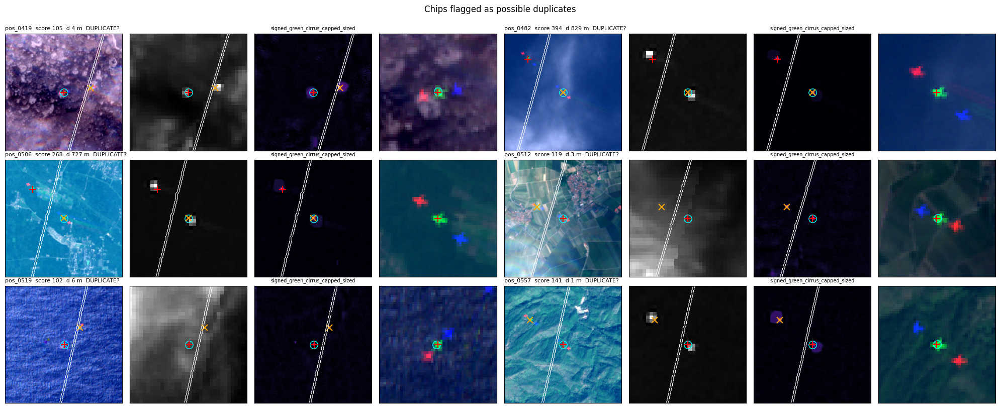

In [12]:
gallery(r[r.duplicate].chip, "Chips flagged as possible duplicates", path=FIG_DIR / "aircraft_detection_duplicates.png")

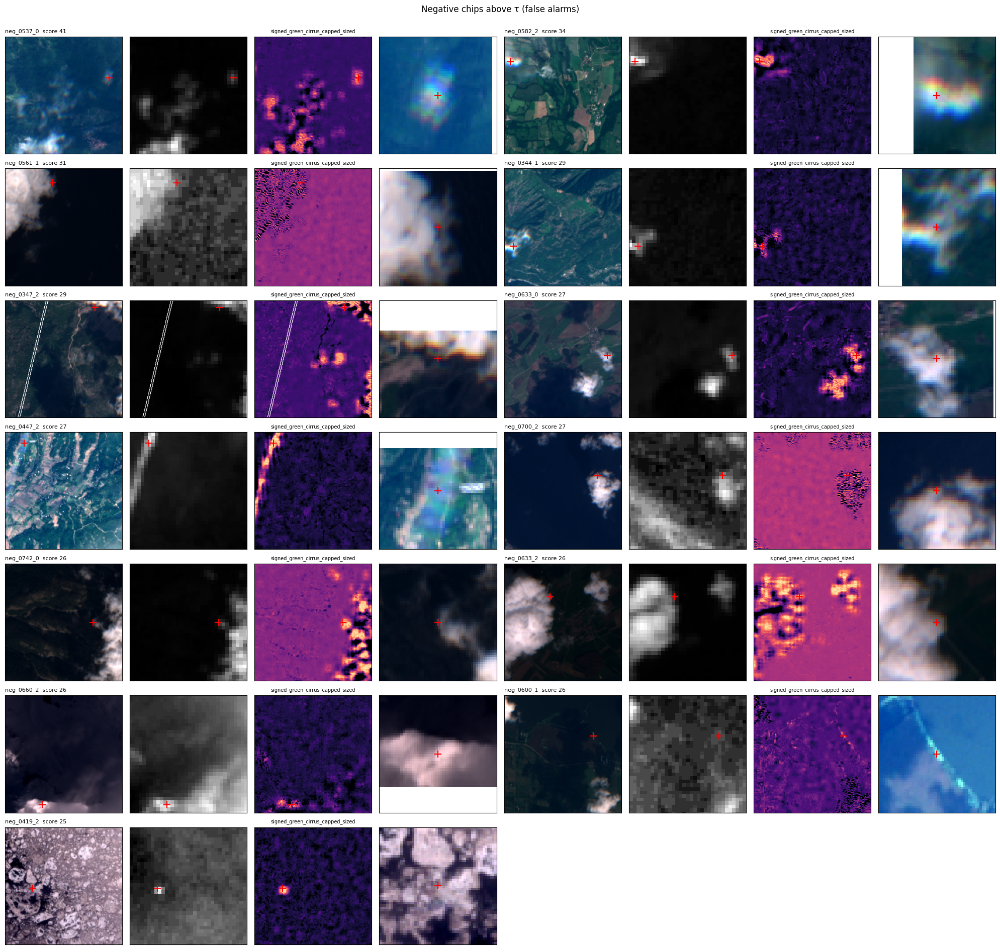

In [13]:
gallery(r[acc & ~pos].sort_values("score", ascending=False).chip, "Negative chips above τ (false alarms)",
        path=FIG_DIR / "aircraft_detection_false_alarms.png")

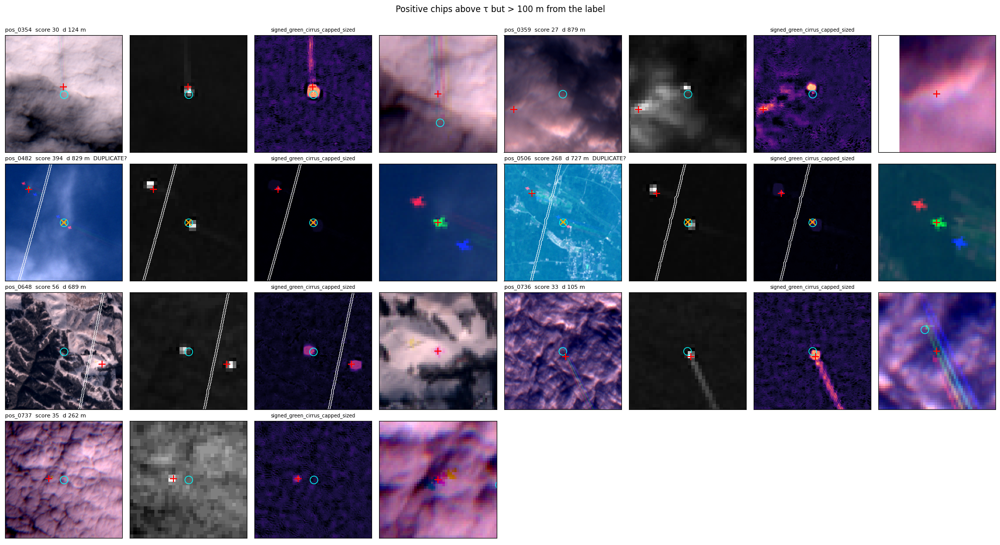

In [14]:
gallery(r[acc & pos & ~near].chip, "Positive chips above τ but > 100 m from the label")

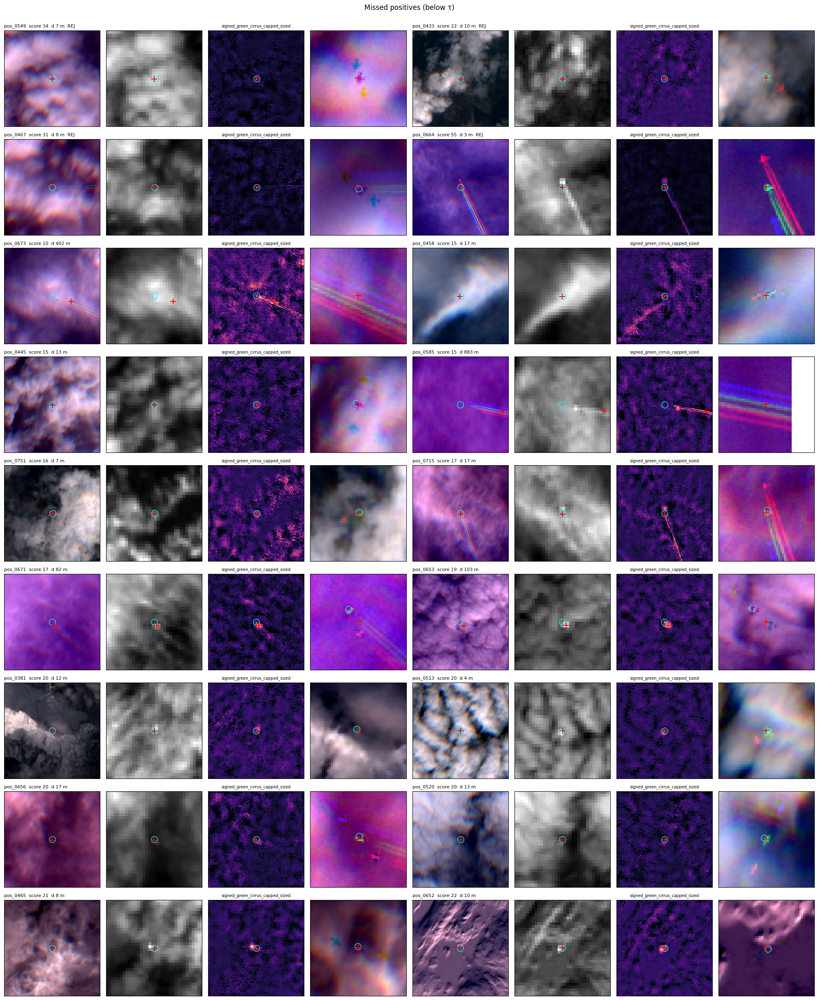

In [15]:
gallery(r[~acc & pos].sort_values("score").chip, "Missed positives (below τ)",
        path=FIG_DIR / "aircraft_detection_misses.png")

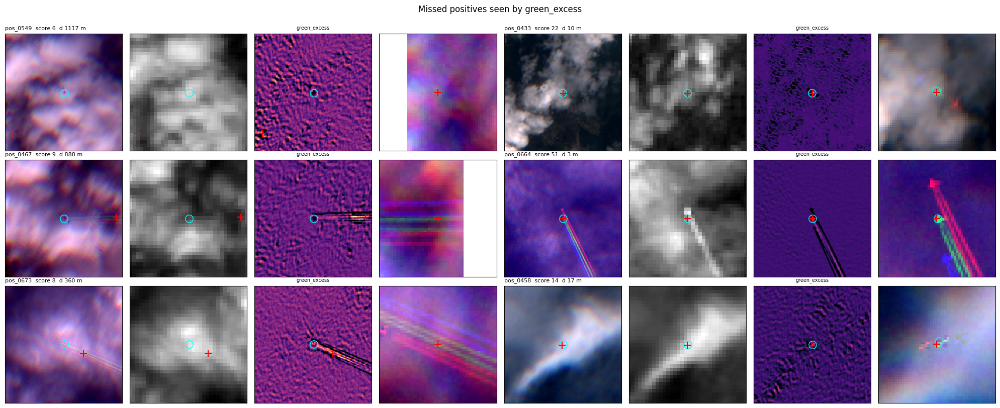

In [16]:
# the same chips seen by another method, e.g. the unsigned green excess
gallery(r[~acc & pos].sort_values("score").chip.head(6), "Missed positives seen by green_excess", method="green_excess")

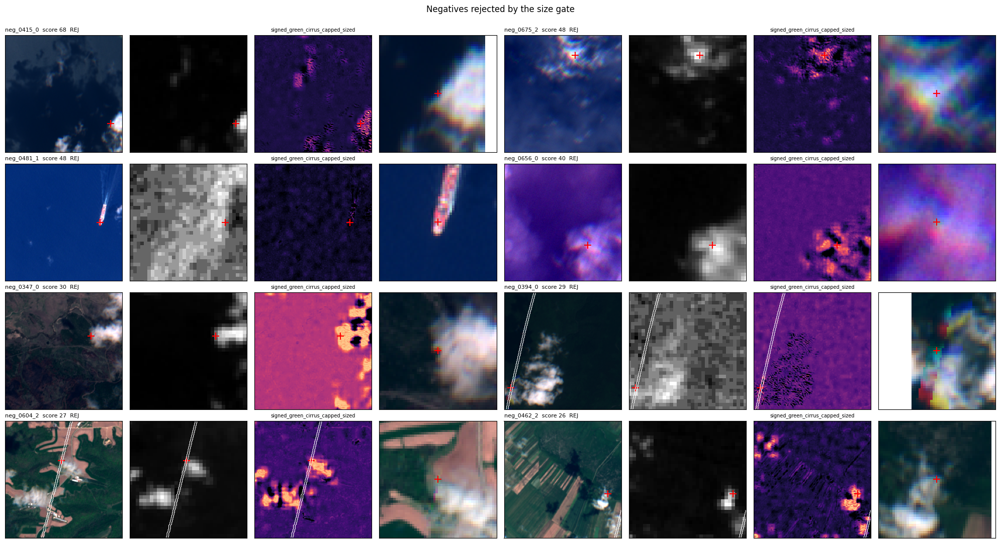

In [17]:
# negatives rejected by the size gate (the cumulus the gate removes)
gallery(r[(r.label == 0) & (r.rejected != "")].sort_values("score_raw", ascending=False).chip.head(8),
        "Negatives rejected by the size gate", path=FIG_DIR / "aircraft_detection_size_rejected.png")

## 9. Error audit (by eye, τ ≈ 25)

- **Signed green was the key step.** Over bright cloud the aircraft is *darker* than its surroundings in
  green. The unsigned methods then latched onto the brighter blue/red ghosts or the B10 blob, which were
  105–160 m from the label. With the signed green, localisation recall rose from 0.95 to 0.98 and every
  remaining accepted positive sits on the green blob.
- **Size gate.** It rejects 118 negatives and 4 positives. Most of the rejected negatives are low cumulus and
  bright cloud edges; one is the moving ship (`neg_0481_1`). Precision rises from 0.936 to 0.948 at almost
  unchanged recall.
- **Duplicates (6 flagged, all genuine).** In every case the two copies lie on neighbouring detectors and the
  detector border runs between them (white line in the gallery). The cumulus cloud flagged before
  (`neg_0675_2`) is no longer flagged: its two peaks are on the same detector, and the size gate rejects it.
  In `pos_0482` and `pos_0506` the copy scores higher than the labelled aircraft, so the detection counts as
  > 100 m.
- **Detector borders.** The final detector rejects detections within 20 m of a border. That removes
  `neg_0394_0` (a cloud edge on the 11|12 seam) without losing any aircraft; at 100 m it would already cost two.
  None of the remaining false alarms lies within 250 m of a border. `neg_0347_2` contains a border, but its
  detection is a cloud edge > 500 m away from it. Dropping all chips within 100 m of a border
  (`drop_near_detector_border`) raises precision to 0.956 but removes 36 of 405 aircraft.
- **Remaining false alarms on negatives (13, specificity 0.989).**
  - Mostly small, bright cumulus below the size limit, and cloud edges with a colour fringe (e.g. `neg_0347_2`,
    `neg_0660_2`).
  - A coastline surf line (`neg_0600_1`) and a bright linear feature (`neg_0447_2`).
  - `neg_0419_2` has a compact B10 spot and might be another aircraft.
  - `neg_0467_2` and `neg_0540_1` (real aircraft) are excluded from the negatives.
- **Missed positives (18).** Most are located correctly but score below τ: faint aircraft over textured,
  bright cloud. Two are pulled onto a long contrail.

**Bottom line.** `signed_green_cirrus_capped_sized` reaches precision 0.950 and recall 0.936 (2-fold CV mean;
worst fold 0.931; pooled τ ≈ 25: P 0.950, R 0.938), with a median localisation error of ~8 m.